## 0. Imports et paramètres

In [2]:
import re
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ds_folder = "data-sample"   # même dossier que dans test.ipynb

## 1. Préparation des données

### 1.1 Lecture

On stocke une session directement comme une **liste Python**. Pour éviter un array de 15000 colonnes avec les sessions les plus longues

In [3]:
# --- Version "séquence" : une ligne = une session, la colonne `tokens` contient la liste des événements ---
def read_sessions(ds_folder, ds_name: str) -> pd.DataFrame:
    has_label = "train" in ds_name
    records = []
    with open(f"{ds_folder}/{ds_name}.csv", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split(",")
            if has_label:
                util, nav, tokens = parts[0], parts[1], parts[2:]
            else:
                util, nav, tokens = None, parts[0], parts[1:]
            records.append({"util": util, "navigateur": nav,
                            "tokens": [t for t in tokens if t != ""]})
    return pd.DataFrame(records)


sessions = read_sessions(ds_folder, "train")
print(sessions.shape)
sessions.head()

(3279, 3)


,util,navigateur,tokens
0,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...


### 1.2 Premiers comptages (statistiques simples)

On regarde combien d'exemples on a **par classe** (les utilisateurs): c'est ce qui conditionne la stratégie d'évaluation.

Sessions : 3279  |  Utilisateurs : 247
count    247.0
mean      13.3
std        8.9
min        4.0
25%        7.0
50%       12.0
75%       16.0
max       75.0
Name: count, dtype: float64


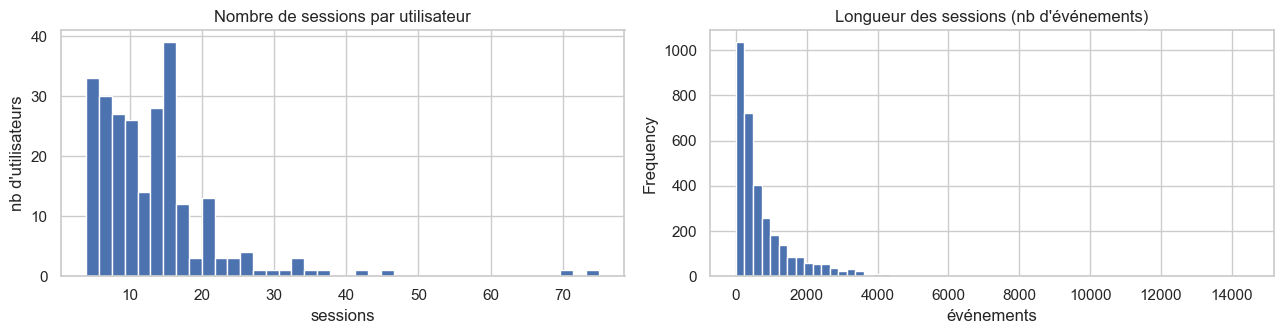

In [4]:
sess_par_user = sessions["util"].value_counts()
print(f"Sessions : {len(sessions)}  |  Utilisateurs : {sessions['util'].nunique()}")
print(sess_par_user.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
sess_par_user.plot(kind="hist", bins=40, ax=ax[0], title="Nombre de sessions par utilisateur")
ax[0].set_xlabel("sessions"); ax[0].set_ylabel("nb d'utilisateurs")
sessions["tokens"].str.len().plot(kind="hist", bins=60, logx=False, ax=ax[1],
                                  title="Longueur des sessions (nb d'événements)")
ax[1].set_xlabel("événements")
plt.tight_layout(); plt.show()

- 247 classes, **très déséquilibrées** (de 4 à 75 sessions). La *accuracy* seule sera trompeuse : on suivra aussi le **F1 macro** (moyenne des F1 de chaque utilisateur, chaque utilisateur pèse autant).

- Les longueurs de session varient de 2 à ~14 000 événements → les **comptages bruts** dépendent surtout de la durée de la session. Il faudra raisonner en **proportions / taux** plutôt qu'en nombres absolus.

### 1.3 Le navigateur

In [5]:
nav_par_user = sessions.groupby("util")["navigateur"].nunique()
print("Utilisateurs ayant utilisé plus d'un navigateur :", (nav_par_user > 1).sum())
sessions["navigateur"].value_counts()

Utilisateurs ayant utilisé plus d'un navigateur : 0


navigateur
Firefox           1466
Google Chrome     1339
Microsoft Edge     451
Opera               23
Name: count, dtype: int64

Chaque utilisateur utilise **toujours le même navigateur**. C'est donc un indicateur légitime et très discriminant (il divise l'espace en 4 groupes),
mais il ne suffit pas : ~1 400 sessions Firefox se partagent entre plus de 100 utilisateurs. On l'encodera en **One Hot Encoding** (cours, *Données hétérogènes*).

> ⚠️ En conditions réelles, si un utilisateur change de navigateur, le modèle risque de se tromper : c'est un indicateur « d'environnement », pas de comportement.

### 1.4 Parsing structuré d'un événement

```
Action [ (écran) ] [ <configuration> ] [ $chaîne$ ] [ 1 ]      ou bien      tN  (marqueur de temps)
```

| Partie | Exemple | Interprétation probable |
|---|---|---|
| Action | `Saisie dans un champ` | type d'interaction (35 valeurs) |
| `(écran)` | `(infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm)` | écran / contrôleur utilisé → **module métier** |
| `<conf>` | `<DEF_03/24>`, `<ACCUEIL_GMAO>`, `<INSTALLATEUR>` | configuration / profil d'affichage — souvent personnelle |
| `$chaîne$` | `$VT$`, `$GP$`, `$TEC$` | chaîne / domaine fonctionnel |
| suffixe `1` | `Saisie dans un champ1` | Modification de la fiche |
| `tN` | `t5`, `t10`… | marqueur toutes les 5 secondes |

Plutôt que plusieurs regex séparées, on décompose chaque événement **une seule fois** en ses 5 composantes.

In [6]:
TOKEN_RE = re.compile(
    r"^(?P<action>[^(<$]+?)"          # nom de l'action
    r"(?:\((?P<ecran>.*)\))?"         # (écran) optionnel
    r"(?:<(?P<conf>[^>]*)>)?"         # <configuration> optionnelle
    r"(?:\$(?P<chaine>[^$]*)\$)?"     # $chaîne$ optionnelle
    r"(?P<suffixe>1)?$"               # suffixe "1" optionnel
)
TIME_RE = re.compile(r"^t(\d+)$")


def parse_token(tok: str):
    # Renvoie un dict {action, ecran, conf, chaine, suffixe} ou None si c'est un marqueur de temps.
    if TIME_RE.match(tok):
        return None
    m = TOKEN_RE.match(tok)
    if m:
        d = m.groupdict()
        d["suffixe"] = d["suffixe"] is not None
        return d
    # Cas rares mal formés : on garde au moins le nom de l'action
    action = re.split(r"[(<$]", tok, maxsplit=1)[0]
    return {"action": action, "ecran": None, "conf": None, "chaine": None, "suffixe": False}


for t in ["Saisie dans un champ(MAINT)<DEF_03/24>1",
          "Exécution d'un bouton<DEF_07/23>$GP$",
          "Sélection d'un écran(infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm)<TELEM_MINIMAL>",
          "t15"]:
    print(f"{t[:70]:<72} -> {parse_token(t)}")

Saisie dans un champ(MAINT)<DEF_03/24>1                                  -> {'action': 'Saisie dans un champ', 'ecran': 'MAINT', 'conf': 'DEF_03/24', 'chaine': None, 'suffixe': True}
Exécution d'un bouton<DEF_07/23>$GP$                                     -> {'action': "Exécution d'un bouton", 'ecran': None, 'conf': 'DEF_07/23', 'chaine': 'GP', 'suffixe': False}
Sélection d'un écran(infologic.orga.modules.OR_FICHIERTRAVAIL.Instance   -> {'action': "Sélection d'un écran", 'ecran': 'infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm', 'conf': 'TELEM_MINIMAL', 'chaine': None, 'suffixe': False}
t15                                                                      -> None


In [7]:
DOMAINE_RE = re.compile(r"^(?:fr\.)?infologic\.(?:[a-z]+\.)?(?P<dom>[a-z]+)\.")
MODULE_RE = re.compile(r"modules\.(?P<mod>[A-Za-z0-9_]+)")


def ecran_vers_module(ecran: str):
    # Renvoie (domaine, module) à partir d'un nom d'écran.
    if not ecran:
        return None, None
    m_mod = MODULE_RE.search(ecran)
    if m_mod:
        module = m_mod["mod"]
        dom = re.match(r"^(?:fr\.)?infologic\.([a-z]+)", ecran)
        domaine = dom.group(1) if dom else module.split("_")[0]
        return domaine, module
    if ecran.startswith(("infologic.", "fr.infologic.")):
        # ex. infologic.core.gui.controllers.BlankController -> domaine "core", module = dernière classe
        parts = ecran.split(".")
        domaine = parts[2] if parts[0] == "fr" else parts[1]
        return domaine, parts[-1]
    # écrans courts (MAINT, DEV, GL_FichierDiscussion…) : préfixe avant "_" comme domaine
    return ecran.split("_")[0], ecran


for e in ["infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm",
          "fr.infologic.ventes.client.modules.fichierbase.assortiment.AssortimentForm",
          "infologic.core.gui.controllers.BlankController", "MAINT", "GL_FichierDiscussion"]:
    print(f"{e:<75} -> {ecran_vers_module(e)}")

infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm                       -> ('orga', 'OR_FICHIERTRAVAIL')
fr.infologic.ventes.client.modules.fichierbase.assortiment.AssortimentForm  -> ('ventes', 'fichierbase')
infologic.core.gui.controllers.BlankController                              -> ('core', 'BlankController')
MAINT                                                                       -> ('MAINT', 'MAINT')
GL_FichierDiscussion                                                        -> ('GL', 'GL_FichierDiscussion')


## 2. Construction des indicateurs

On propose **6 familles d'indicateurs**, chacune répondant à une question différente sur « qui est derrière la session » :

| # | Famille | Question | Type |
|---|---|---|---|
| F1 | Contexte | Avec quel outil travaille-t-il ? | catégorielle (navigateur) |
| F2 | Rythme & durée | À quelle vitesse et combien de temps travaille-t-il ? | numérique |
| F3 | Profil d'actions | Quelles actions fait-il, en proportion ? | numérique (35 proportions) |
| F4 | Style d'interaction | *Comment* fait-il les choses (clavier vs souris, erreurs, retours…) ? | numérique (ratios) |
| F5 | Diversité | Reste-t-il sur peu d'écrans ou navigue-t-il partout ? | numérique |
| F6 | Contenu (sac de mots) | **Quels** écrans, configurations, chaînes, modules utilise-t-il ? Dans quel ordre enchaîne-t-il les actions ? | texte → TF-IDF |

*(Le double-clic, le chaînage et les erreurs sont déjà couverts par les proportions de F3 : on ne les duplique pas ici.)*

Toutes les variables sont calculées **par session** (une ligne = une session) : c'est indispensable pour pouvoir prédire l'utilisateur d'une nouvelle session.


### 2.1 Décomposition de chaque session

On parcourt chaque session une seule fois et on produit : la liste des événements parsés, et le découpage en **fenêtres de 5 s** (entre deux marqueurs `tN`).

In [8]:
def decompose_session(tokens):
    events, fenetres, courant, t_max = [], [], 0, 0
    for tok in tokens:
        m = TIME_RE.match(tok)
        if m:
            t_max = max(t_max, int(m.group(1)))
            fenetres.append(courant)   # nb d'actions dans la fenêtre de 5 s qui se termine
            courant = 0
            continue
        ev = parse_token(tok)
        ev["domaine"], ev["module"] = ecran_vers_module(ev["ecran"])
        events.append(ev)
        courant += 1
    fenetres.append(courant)           # dernière fenêtre (incomplète)
    return events, fenetres, t_max


parsed = sessions["tokens"].apply(decompose_session)
sessions["events"] = parsed.str[0]
sessions["fenetres"] = parsed.str[1]
sessions["duree_s"] = parsed.str[2]

# Vocabulaire des actions (35 types)
ACTIONS = sorted({ev["action"] for evs in sessions["events"] for ev in evs})
print(len(ACTIONS), "types d'actions")
ACTIONS

35 types d'actions


['Action de table',
 "Affichage d'un toast",
 "Affichage d'une arborescence",
 "Affichage d'une dialogue",
 "Affichage d'une erreur",
 'Chainage',
 'Clic long',
 'Clic sur une checkbox',
 "Clic sur une grille d'historique de recherche",
 "Création d'un écran",
 "Dissimulation d'une arborescence",
 'Double-clic',
 "Démarrage serveur d'application Tomcat",
 "Désélection d'un flag",
 "Désélection d'un élément",
 'Entrée en saisie dans un formulaire',
 'Erreur système grave',
 "Exécution d'un bouton",
 "Fermeture d'un panel",
 "Fermeture d'une dialogue",
 'Fermeture de session',
 'Filtrage / Tri',
 "Lancement d'un tableau de bord",
 "Lancement d'une action générique",
 "Lancement d'une action infocentre",
 "Lancement d'une stat",
 "Ouverture d'un panel",
 'Raccourci',
 "Raccourci dans l'édition de table",
 'Retour sur un écran',
 'Saisie dans un champ',
 "Sélection d'un flag",
 "Sélection d'un écran",
 "Sélection d'un élément",
 'Sélection d’un onglet']

In [9]:
# Vérification du constat : écarts entre deux marqueurs tN consécutifs
ecarts = Counter()
for toks in sessions["tokens"]:
    ts = [int(t[1:]) for t in toks if TIME_RE.match(t)]
    ecarts.update(np.diff(ts).tolist())
print("Écarts entre marqueurs consécutifs :", dict(ecarts.most_common()))


def features_rythme(row):
    f = np.array(row["fenetres"]) if row["fenetres"] else np.array([0])
    n = len(row["events"])
    duree = max(row["duree_s"], 5)
    return {
        "duree_s": row["duree_s"],
        "nb_actions": n,
        "duree": row["duree_s"],
        "actions_par_min": n / duree * 60,
        "cadence_moy": f.mean(),
        "cadence_std": f.std(),
        "cadence_max": f.max(),
    }

F2 = pd.DataFrame(sessions.apply(features_rythme, axis=1).tolist())
F2.describe().T.round(2)

Écarts entre marqueurs consécutifs : {5: 489467, 0: 24887, 10: 52, 15: 1}


,count,mean,std,min,25%,50%,75%,max
duree_s,3279.0,751.53,1006.28,5.0,185.00,395.00,945.00,11790.00
nb_actions,3279.0,692.36,1005.87,0.0,153.00,340.00,818.50,11977.00
duree,3279.0,751.53,1006.28,5.0,185.00,395.00,945.00,11790.00
actions_par_min,3279.0,56.28,23.30,0.0,44.00,52.85,63.97,556.00
cadence_moy,3279.0,4.38,1.65,0.0,3.45,4.14,4.99,34.75
cadence_std,3279.0,4.98,3.76,0.0,3.35,4.42,5.74,112.81
cadence_max,3279.0,32.41,49.74,0.0,17.00,25.00,37.00,1859.00


### 2.3 F3 — Profil d'actions (proportions)

En **proportions** plutôt qu'en comptes : une session de 2 h et une de 5 min du même utilisateur doivent avoir un profil proche.

In [10]:
def code_action(a):
    # nom de colonne court et sans accents/espaces
    import unicodedata
    a = unicodedata.normalize("NFKD", a).encode("ascii", "ignore").decode()
    return "p_" + re.sub(r"[^A-Za-z0-9]+", "_", a).strip("_").lower()

ACTION_COL = {a: code_action(a) for a in ACTIONS}

def features_actions(events):
    c = Counter(ev["action"] for ev in events)
    n = max(len(events), 1)
    d = {ACTION_COL[a]: c.get(a, 0) / n for a in ACTIONS}
    return d

F3 = pd.DataFrame(sessions["events"].apply(features_actions).tolist())
F3.mean().sort_values(ascending=False).head(12).round(3)

p_execution_d_un_bouton                            0.236
p_saisie_dans_un_champ                             0.126
p_selection_d_un_ecran                             0.078
p_fermeture_d_une_dialogue                         0.078
p_affichage_d_une_dialogue                         0.076
p_lancement_d_une_action_generique                 0.043
p_creation_d_un_ecran                              0.042
p_selection_dun_onglet                             0.039
p_raccourci                                        0.033
p_chainage                                         0.031
p_double_clic                                      0.027
p_clic_sur_une_grille_d_historique_de_recherche    0.024
dtype: float64

### 2.4 F4 — Style d'interaction (ratios « métier »)

Deux personnes qui font le même travail ne le font pas de la même manière. Ces ratios cherchent à capturer des **habitudes** :

| Indicateur | Ce qu'il capture |
|---|---|
| `ratio_clavier` = raccourcis / (raccourcis + boutons) | utilisateur clavier vs souris |
| `ratio_retour` = retours / sélections d'écran | navigue « en arrière » ou ouvre de nouveaux écrans |
| `ratio_saisie_formulaire` = entrées en saisie / saisies dans un champ | saisie longue ou ponctuelle |
| `taux_suffixe_1` | part des modifications dans la session `1` |
| `Part d'erreur sur les éditions` | Fréquence d'erreur en mode édition |
| `taux_avec_ecran / conf / chaine` | part des événements renseignant ces informations |
| `ratio_recherche` | usage de l'historique de recherche et des filtres |

In [11]:
def ratio(a, b):
    return a / b if b else 0.0


def features_style(events):
    c = Counter(ev["action"] for ev in events)
    n = max(len(events), 1)
    g = c.get
    return {
        "ratio_clavier": ratio(g("Raccourci", 0) + g("Raccourci dans l'édition de table", 0),
                               g("Raccourci", 0) + g("Exécution d'un bouton", 0)),
        "ratio_retour": ratio(g("Retour sur un écran", 0),
                              g("Sélection d'un écran", 0) + g("Retour sur un écran", 0)),
        "ratio_saisie_formulaire": ratio(g("Entrée en saisie dans un formulaire", 0),
                                         g("Saisie dans un champ", 0) + 1),
        "ratio_recherche": ratio(g("Clic sur une grille d'historique de recherche", 0) + g("Filtrage / Tri", 0), n),
        "ratio_pilotage": ratio(g("Lancement d'un tableau de bord", 0) + g("Lancement d'une stat", 0), n),
        "taux_suffixe_1": ratio(sum(ev["suffixe"] for ev in events), n),
        "taux_erreur_1": ratio(g("Affichage d'une erreur", 0), 
                               sum(ev["suffixe"] for ev in events)),
        "taux_avec_ecran": ratio(sum(ev["ecran"] is not None for ev in events), n),
        "taux_avec_conf": ratio(sum(ev["conf"] is not None for ev in events), n),
        "taux_avec_chaine": ratio(sum(ev["chaine"] is not None for ev in events), n),


    }

F4 = pd.DataFrame(sessions["events"].apply(features_style).tolist())
F4.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ratio_clavier,3279.0,0.108,0.158,0.0,0.000,0.020,0.171,0.986
ratio_retour,3279.0,0.210,0.251,0.0,0.025,0.111,0.300,1.000
ratio_saisie_formulaire,3279.0,0.293,1.347,0.0,0.000,0.000,0.000,28.500
ratio_recherche,3279.0,0.039,0.057,0.0,0.000,0.007,0.065,0.317
ratio_pilotage,3279.0,0.024,0.038,0.0,0.000,0.007,0.032,0.486
taux_suffixe_1,3279.0,0.155,0.188,0.0,0.011,0.091,0.224,0.908
taux_erreur_1,3279.0,0.082,0.376,0.0,0.000,0.008,0.050,10.000
taux_avec_ecran,3279.0,0.139,0.070,0.0,0.088,0.132,0.177,1.000
taux_avec_conf,3279.0,0.049,0.035,0.0,0.023,0.044,0.069,0.238
taux_avec_chaine,3279.0,0.124,0.150,0.0,0.000,0.058,0.221,0.719


### 2.5 F5 — Diversité de la navigation

Combien d'écrans, de modules, de configurations et de chaînes **différents** la session touche-t-elle ?

In [12]:
def features_diversite(events):
    cnt = {k: Counter(ev[k] for ev in events if ev[k]) for k in ["ecran", "module", "domaine", "conf", "chaine"]}
    d = {}
    for k, c in cnt.items():
        d[f"nb_{k}_distincts"] = len(c)
    return d

F5 = pd.DataFrame(sessions["events"].apply(features_diversite).tolist())
F5.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
nb_ecran_distincts,3279.0,10.70,5.85,0.0,6.0,9.0,14.0,42.0
nb_module_distincts,3279.0,10.02,5.27,0.0,6.0,9.0,13.0,35.0
nb_domaine_distincts,3279.0,6.55,3.18,0.0,4.0,6.0,8.0,21.0
nb_conf_distincts,3279.0,5.02,3.13,0.0,3.0,4.0,7.0,24.0
nb_chaine_distincts,3279.0,2.22,2.78,0.0,0.0,1.0,3.0,23.0


### 2.7 Table finale des indicateurs

In [13]:
NUM_FAMILIES = {
    "F2_rythme": list(F2.columns),
    "F3_actions": list(F3.columns),
    "F4_style": list(F4.columns),
    "F5_diversite": list(F5.columns),
}
NUM_COLS = sum(NUM_FAMILIES.values(), [])

df_feat = pd.concat(
    [sessions[["util", "navigateur"]], F2, F3, F4, F5], axis=1
)
print(df_feat.shape, "->", len(NUM_COLS), "indicateurs numériques + navigateur + 2 documents texte")
print("Valeurs manquantes :", df_feat[NUM_COLS].isna().sum().sum())
df_feat.head()

(3279, 59) -> 57 indicateurs numériques + navigateur + 2 documents texte
Valeurs manquantes : 0


,util,navigateur,duree_s,nb_actions,duree,actions_par_min,cadence_moy,cadence_std,cadence_max,p_action_de_table,p_affichage_d_un_toast,p_affichage_d_une_arborescence,p_affichage_d_une_dialogue,p_affichage_d_une_erreur,p_chainage,p_clic_long,p_clic_sur_une_checkbox,p_clic_sur_une_grille_d_historique_de_recherche,p_creation_d_un_ecran,p_dissimulation_d_une_arborescence,p_double_clic,p_demarrage_serveur_d_application_tomcat,p_deselection_d_un_flag,p_deselection_d_un_element,p_entree_en_saisie_dans_un_formulaire,p_erreur_systeme_grave,p_execution_d_un_bouton,p_fermeture_d_un_panel,p_fermeture_d_une_dialogue,p_fermeture_de_session,p_filtrage_tri,p_lancement_d_un_tableau_de_bord,p_lancement_d_une_action_generique,p_lancement_d_une_action_infocentre,p_lancement_d_une_stat,p_ouverture_d_un_panel,p_raccourci,p_raccourci_dans_l_edition_de_table,p_retour_sur_un_ecran,p_saisie_dans_un_champ,p_selection_d_un_flag,p_selection_d_un_ecran,p_selection_d_un_element,p_selection_dun_onglet,ratio_clavier,ratio_retour,ratio_saisie_formulaire,ratio_recherche,ratio_pilotage,taux_suffixe_1,taux_erreur_1,taux_avec_ecran,taux_avec_conf,taux_avec_chaine,nb_ecran_distincts,nb_module_distincts,nb_domaine_distincts,nb_conf_distincts,nb_chaine_distincts
0,nuh,Firefox,2905,2514,2905,51.924269,4.087805,3.661103,22,0.004375,0.123707,0.000398,0.139220,0.002387,0.003182,0.0,0.0,0.000398,0.028640,0.0,0.034606,0.000000,0.0,0.000000,0.000000,0.0,0.277645,0.000000,0.146778,0.000398,0.064041,0.0,0.049324,0.0,0.033811,0.000000,0.000000,0.0,0.000796,0.078759,0.00000,0.009149,0.000000,0.002387,0.000000,0.080000,0.000000,0.064439,0.033811,0.001591,1.500000,0.075975,0.002784,0.357597,7,7,4,3,2
1,muz,Google Chrome,230,90,230,23.478261,1.914894,1.268770,6,0.000000,0.011111,0.000000,0.022222,0.000000,0.033333,0.0,0.0,0.000000,0.033333,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.366667,0.000000,0.022222,0.000000,0.000000,0.0,0.055556,0.0,0.000000,0.000000,0.011111,0.0,0.000000,0.377778,0.00000,0.033333,0.000000,0.033333,0.029412,0.000000,0.000000,0.000000,0.000000,0.288889,0.000000,0.088889,0.044444,0.477778,5,5,4,2,2
2,zrx,Microsoft Edge,750,608,750,48.640000,3.823899,3.740875,22,0.009868,0.011513,0.001645,0.057566,0.000000,0.052632,0.0,0.0,0.118421,0.059211,0.0,0.036184,0.000000,0.0,0.018092,0.000000,0.0,0.200658,0.001645,0.062500,0.000000,0.001645,0.0,0.057566,0.0,0.000000,0.001645,0.064145,0.0,0.006579,0.075658,0.00000,0.111842,0.016447,0.034539,0.242236,0.055556,0.000000,0.120066,0.000000,0.082237,0.000000,0.154605,0.057566,0.085526,17,15,12,7,2
3,pou,Firefox,1445,886,1445,36.788927,2.821656,2.856445,22,0.007901,0.002257,0.000000,0.047404,0.001129,0.025959,0.0,0.0,0.136569,0.024831,0.0,0.002257,0.001129,0.0,0.000000,0.000000,0.0,0.314898,0.000000,0.047404,0.001129,0.005643,0.0,0.029345,0.0,0.113995,0.000000,0.000000,0.0,0.019187,0.094808,0.06772,0.056433,0.000000,0.000000,0.000000,0.253731,0.000000,0.142212,0.113995,0.072235,0.015625,0.281038,0.010158,0.229120,10,10,6,4,1
4,ald,Google Chrome,275,173,275,37.745455,2.836066,2.759070,15,0.017341,0.005780,0.000000,0.057803,0.000000,0.023121,0.0,0.0,0.057803,0.057803,0.0,0.011561,0.000000,0.0,0.000000,0.127168,0.0,0.346821,0.000000,0.057803,0.005780,0.000000,0.0,0.040462,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.080925,0.00000,0.109827,0.000000,0.000000,0.000000,0.000000,1.466667,0.057803,0.000000,0.011561,0.000000,0.121387,0.040462,0.063584,8,8,7,4,2


## 3. Exploration

### 3.1 Redondance : corrélations entre indicateurs

Le cours recommande de filtrer les variables « trop corrélées entre elles ». On repère les paires avec $|r| > 0.9$.

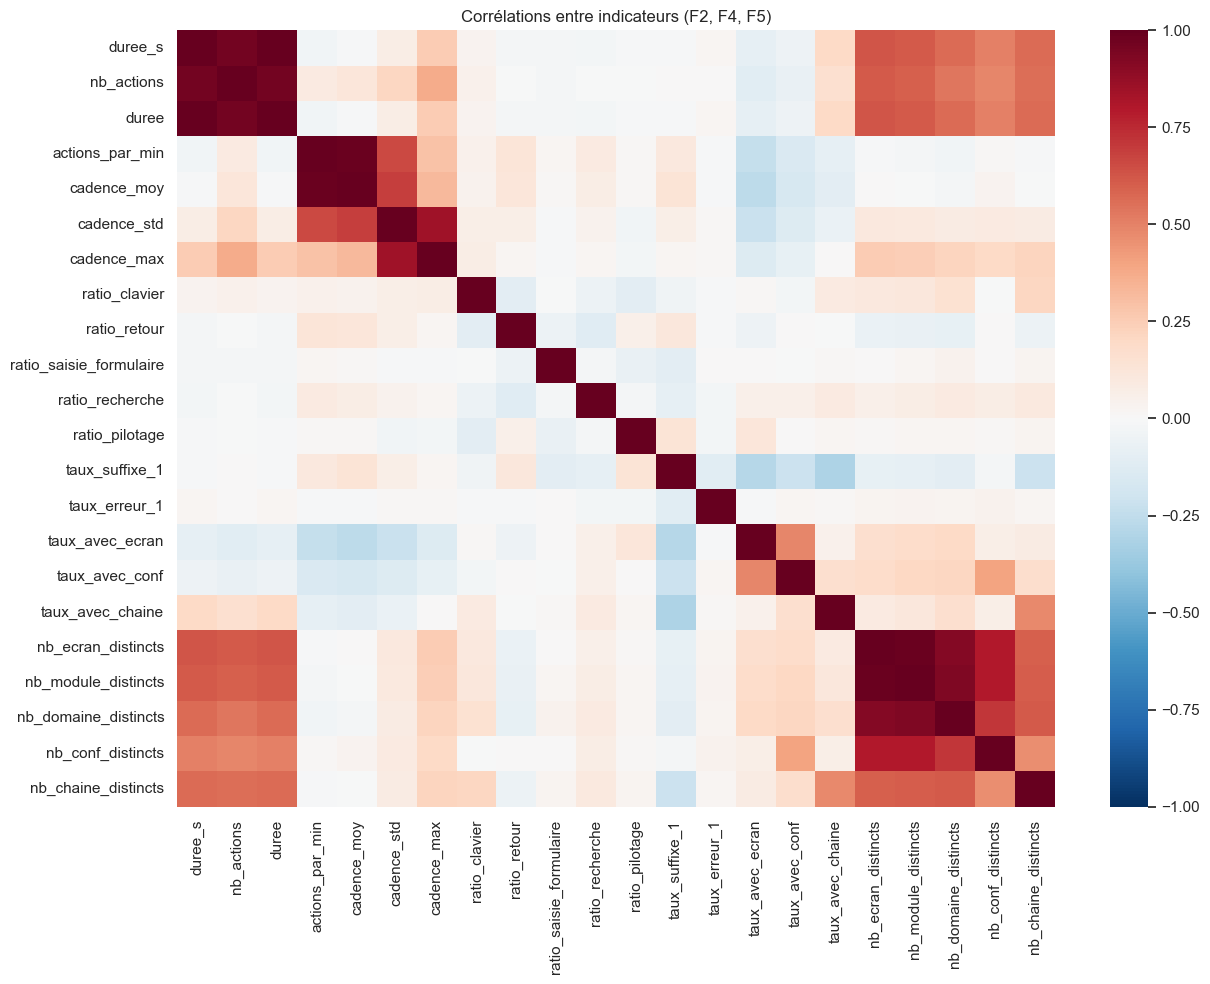

duree_s                     duree                         1.000000
p_deselection_d_un_element  p_selection_d_un_element      0.998073
nb_ecran_distincts          nb_module_distincts           0.987363
actions_par_min             cadence_moy                   0.986809
p_affichage_d_une_dialogue  p_fermeture_d_une_dialogue    0.967658
nb_actions                  duree                         0.965254
duree_s                     nb_actions                    0.965254
p_raccourci                 ratio_clavier                 0.940782
nb_module_distincts         nb_domaine_distincts          0.933913
nb_ecran_distincts          nb_domaine_distincts          0.920187
dtype: float64

In [14]:
X_num = df_feat[NUM_COLS]
corr = X_num.drop(columns=NUM_FAMILIES["F3_actions"]).corr()   # F3 à part pour la lisibilité

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title("Corrélations entre indicateurs (F2, F4, F5)")
plt.tight_layout(); plt.show()

full_corr = X_num.corr().abs()
upper = full_corr.where(np.triu(np.ones(full_corr.shape, dtype=bool), k=1))
paires = upper.stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
paires

### 3.2 Pouvoir discriminant de chaque indicateur

Un bon indicateur pour reconnaître un utilisateur doit **varier peu au sein des sessions d'un même utilisateur** et **beaucoup entre utilisateurs**.
C'est exactement ce que mesure la statistique **F de l'ANOVA** (variance inter-classes / variance intra-classes). On la complète par l'**information mutuelle**, qui capte aussi les relations non linéaires.

c:\Users\duran\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\duran\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\duran\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\duran\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\duran\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(e

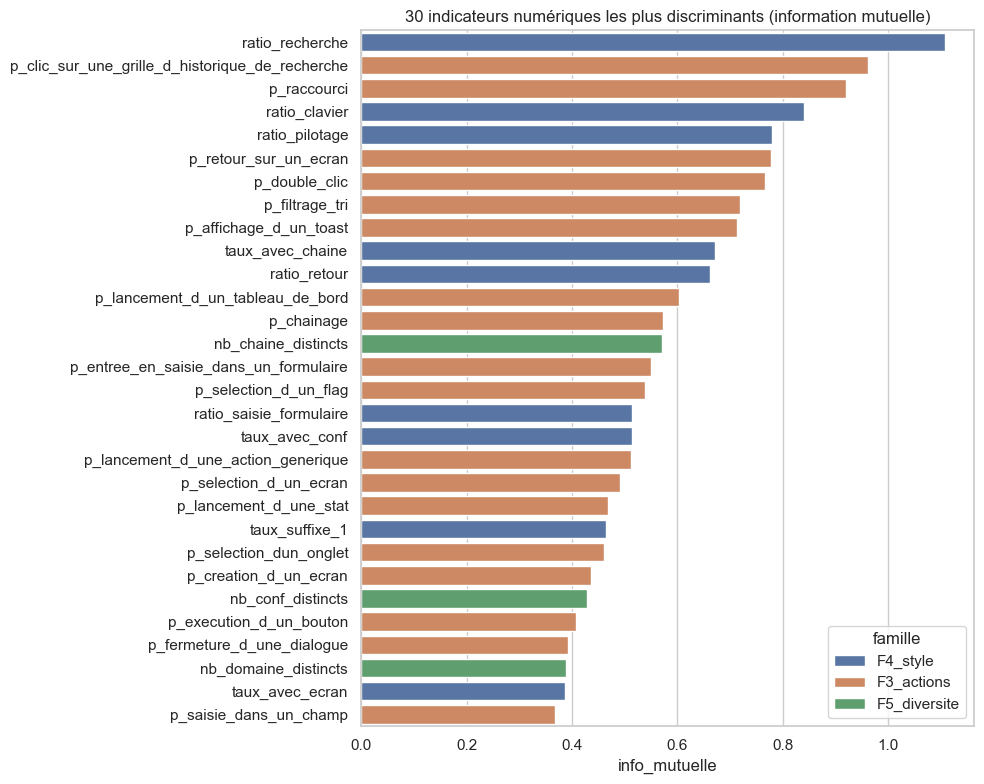

,F_anova,info_mutuelle,famille
ratio_recherche,151.488,1.108,F4_style
p_clic_sur_une_grille_d_historique_de_recherche,137.209,0.963,F3_actions
p_raccourci,50.223,0.920,F3_actions
ratio_clavier,44.433,0.841,F4_style
ratio_pilotage,39.845,0.781,F4_style
p_retour_sur_un_ecran,81.138,0.777,F3_actions
p_double_clic,39.200,0.767,F3_actions
p_filtrage_tri,215.195,0.719,F3_actions
p_affichage_d_un_toast,69.118,0.713,F3_actions
taux_avec_chaine,23.739,0.671,F4_style


In [15]:
y = df_feat["util"].values
F_stat, _ = f_classif(X_num, y)
MI = mutual_info_classif(X_num, y, random_state=RANDOM_STATE)

fam_of = {c: fam for fam, cols in NUM_FAMILIES.items() for c in cols}
discr = (pd.DataFrame({"F_anova": F_stat, "info_mutuelle": MI}, index=NUM_COLS)
           .assign(famille=lambda d: d.index.map(fam_of))
           .sort_values("info_mutuelle", ascending=False))

fig, ax = plt.subplots(figsize=(10, 8))
top = discr.head(30)
sns.barplot(data=top.reset_index(), y="index", x="info_mutuelle", hue="famille", dodge=False, ax=ax)
ax.set_title("30 indicateurs numériques les plus discriminants (information mutuelle)")
ax.set_ylabel("")
plt.tight_layout(); plt.show()
discr.head(15).round(3)

In [16]:
# Et les moins utiles : candidats à la suppression
discr.tail(10).round(4)

,F_anova,info_mutuelle,famille
p_dissimulation_d_une_arborescence,2.9270,0.1623,F3_actions
p_selection_d_un_element,6.6456,0.1609,F3_actions
p_ouverture_d_un_panel,5.4126,0.1594,F3_actions
p_deselection_d_un_element,6.5002,0.1509,F3_actions
p_demarrage_serveur_d_application_tomcat,1.7363,0.1433,F3_actions
p_deselection_d_un_flag,228.4101,0.0868,F3_actions
p_raccourci_dans_l_edition_de_table,4.3340,0.0471,F3_actions
p_clic_long,13.7368,0.0468,F3_actions
p_lancement_d_une_action_infocentre,1.7793,0.0229,F3_actions
p_erreur_systeme_grave,0.7592,0.0000,F3_actions


### 3.3 Visualiser la signature de quelques utilisateurs

Boxplots des indicateurs les plus discriminants pour les 8 utilisateurs ayant le plus de sessions : si les boîtes sont bien séparées, l'indicateur « reconnaît » l'utilisateur.

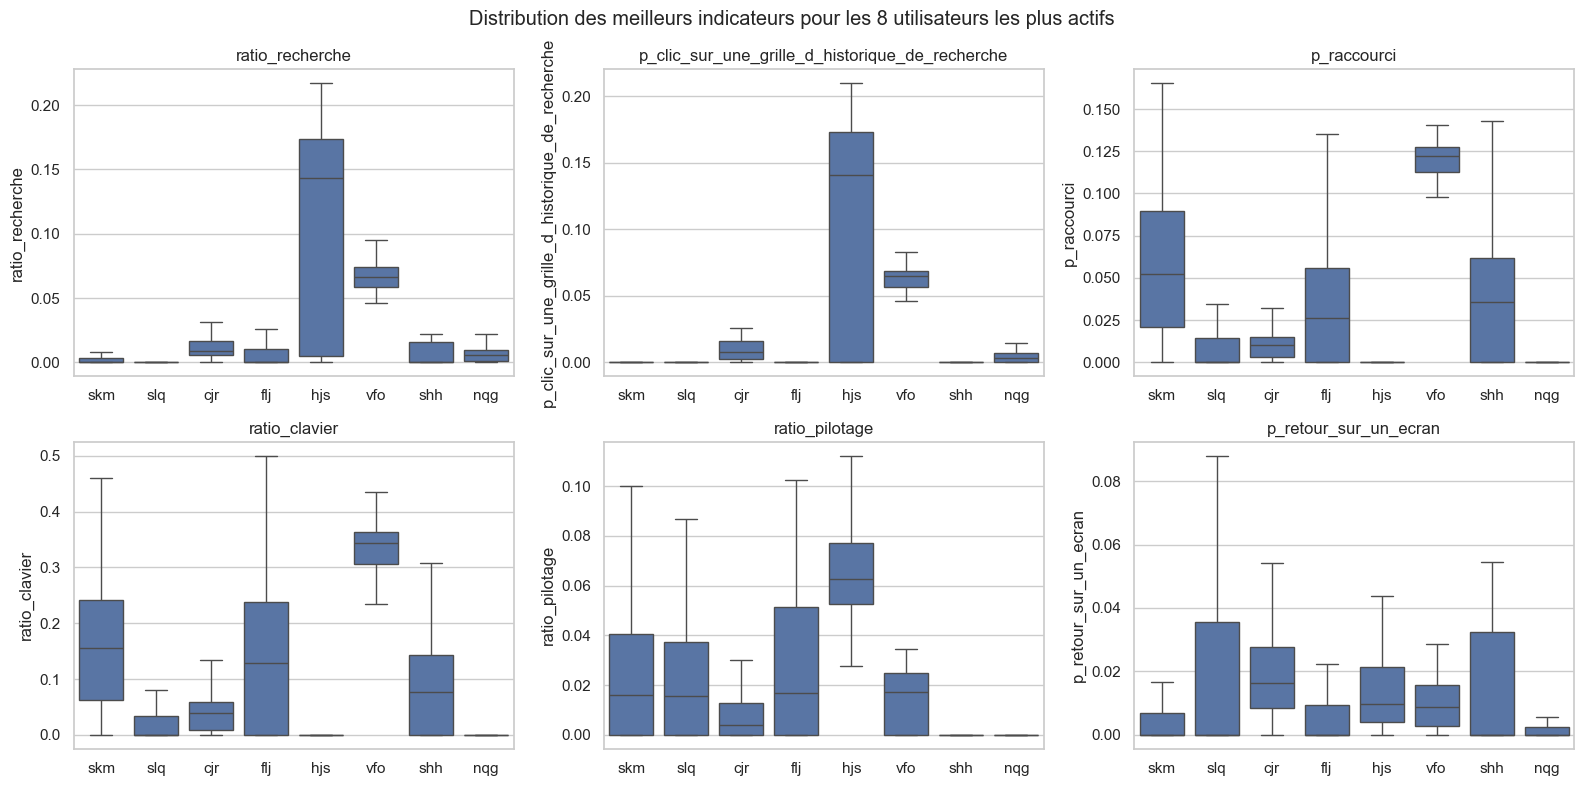

In [17]:
top_users = sess_par_user.index[:8]
sub = df_feat[df_feat["util"].isin(top_users)]
best = discr.index[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), best):
    sns.boxplot(data=sub, x="util", y=col, ax=ax, order=top_users, showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Distribution des meilleurs indicateurs pour les 8 utilisateurs les plus actifs")
plt.tight_layout(); plt.show()

## 4. Classification supervisée

### 4.1 Protocole d'évaluation

- **Validation croisée stratifiée à 4 plis** (`StratifiedKFold`) : chaque session sert une fois en test ; la stratification garantit que chaque utilisateur est présent dans chaque pli (minimum 4 sessions).
- Toutes les transformations (normalisation, TF-IDF, OHE) sont dans un **`Pipeline`** : elles sont apprises **uniquement sur les plis d'apprentissage**. Sinon, l'IDF ou la moyenne/écart-type « verraient » le test → estimation trop optimiste.
- Métriques : **accuracy** et **F1 macro** (robuste au déséquilibre).

In [25]:
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
X = df_feat.drop(columns=["util"])
y = df_feat["util"].values
resultats = {}


def evaluer(nom, modele, X_=X, n_jobs=-1):
    s = cross_validate(modele, X_, y, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=n_jobs)
    resultats[nom] = {"accuracy": s["test_accuracy"].mean(), "acc_std": s["test_accuracy"].std(),
                      "f1_macro": s["test_f1_macro"].mean()}
    r = resultats[nom]
    print(f"{nom:<45} accuracy = {r['accuracy']:.3f} ± {r['acc_std']:.3f}   F1 macro = {r['f1_macro']:.3f}")

In [26]:
prep_num = ColumnTransformer([
    ("nav", OneHotEncoder(handle_unknown="ignore"), ["navigateur"]),
    ("num", "passthrough", NUM_COLS),
])
rf_num = Pipeline([("prep", prep_num),
                   ("clf", RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=RANDOM_STATE))])
evaluer("RF — indicateurs numériques F1-F5", rf_num, n_jobs=1)  # la forêt est déjà parallélisée

RF — indicateurs numériques F1-F5             accuracy = 0.866 ± 0.012   F1 macro = 0.847


### 4.2 Importance des variables numériques (forêt aléatoire)

RF numérique — accuracy sur test 25 % : 0.863


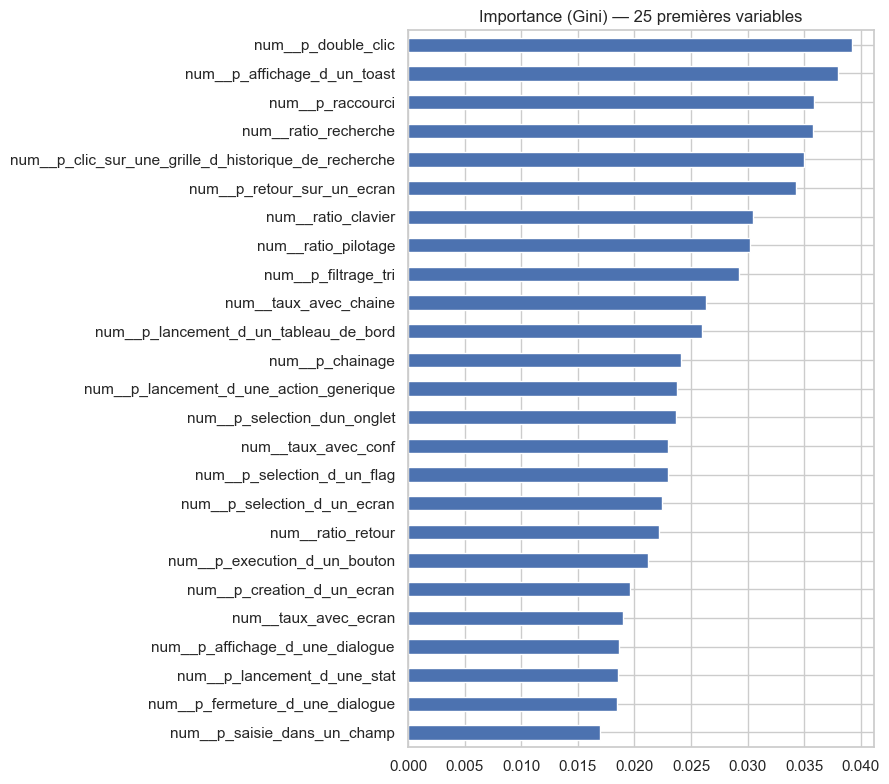

In [20]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
rf_num.fit(X_tr, y_tr)
print(f"RF numérique — accuracy sur test 25 % : {accuracy_score(y_te, rf_num.predict(X_te)):.3f}")

noms = rf_num.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_num.named_steps["clf"].feature_importances_, index=noms).sort_values(ascending=False)
imp.head(25)[::-1].plot(kind="barh", figsize=(9, 8), title="Importance (Gini) — 25 premières variables")
plt.tight_layout(); plt.show()

## 5. Prédiction sur `test.csv`

On ré-entraîne le modèle sur **toutes** les sessions d'apprentissage, puis on prédit les sessions de test (qui n'ont pas de colonne `util`).

In [33]:
import os

def preparer(df_sess):
    # Applique exactement la même chaîne de construction d'indicateurs à un nouveau jeu de sessions.
    p = df_sess["tokens"].apply(decompose_session)
    df_sess = df_sess.assign(events=p.str[0], fenetres=p.str[1], duree_s=p.str[2])

    f = pd.concat([
        pd.DataFrame(df_sess.apply(features_rythme, axis=1).tolist()),
        pd.DataFrame(df_sess["events"].apply(features_actions).tolist()),
        pd.DataFrame(df_sess["events"].apply(features_style).tolist()),
        pd.DataFrame(df_sess["events"].apply(features_diversite).tolist()),
    ], axis=1)
    return pd.concat([df_sess[["navigateur"]].reset_index(drop=True), f], axis=1)


if os.path.exists(f"{ds_folder}/test.csv"):
    test_sessions = read_sessions(ds_folder, "test")
    X_test = preparer(test_sessions)[X.columns]
    final_model = rf_num.fit(X, y)
    test_sessions["prediction"] = final_model.predict(X_test)
    test_sessions["RowId"] = range(1, len(test_sessions) + 1)
    test_sessions[["RowId", "prediction"]].to_csv("predictions_v1.csv", index=False)
    display(test_sessions[["RowId", "prediction"]].head())
else:
    print("Pas de test.csv dans", ds_folder, "— étape ignorée.")

,RowId,prediction
0,1,hzx
1,2,prb
2,3,jmq
3,4,psg
4,5,cvw
